In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina' # hig-res plots for a Retina display

# Euler Method Examples

Solve the following equation:

\begin{equation}
\frac{d \xi}{dt}=-2t^3 +12t^2 - 20t +8.8
\end{equation}

using and explict Euler method. Solve it from $t=0$ to $t=5$. Take the initial condition as being $\xi(t=0)=1$.

## Global input

In [2]:
# input the needed conditions
tstart = 0
tend = 5
xi0 = 1

## The analytic solution

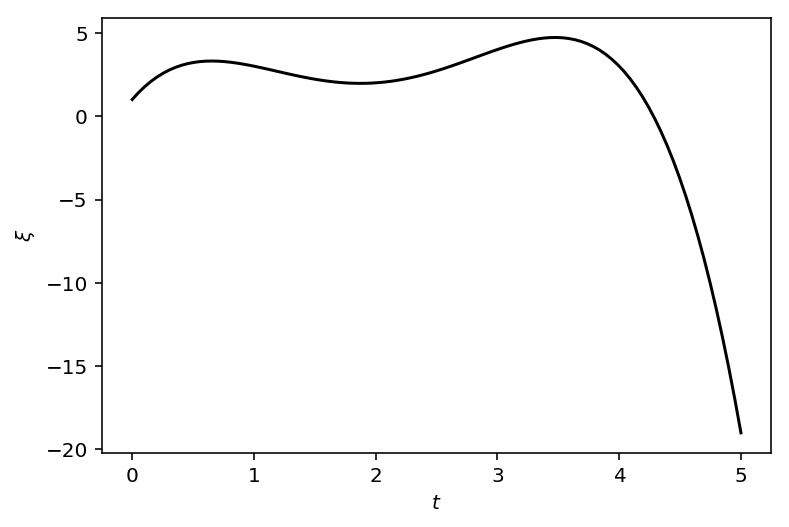

In [3]:
# define the array
t_a = np.linspace(tstart, tend,100)
xi_a = 1+8.5*t_a-10*t_a**2+4*t_a**3-0.5*t_a**4

# plot the analytic solution
fig, ax = plt.subplots()
ax.plot(t_a,xi_a, 'k') # make the line black 
ax.set_xlabel('$t$')
ax.set_ylabel(r'$\xi$');

## Initial numeric solution

The new input needed is the value of $\Delta t$

In [4]:
# input
dt = 0.5

# setup the array
t = np.arange(0,tend,dt)
N = len(t)

xi = np.zeros(N)
xi[0]=xi0

# calculate xi numerically

for i in range(0,N-1):
    xi[i+1]=xi[i]+dt*(-2*t[i]**3+12*t[i]**2-20*t[i]+8.5)

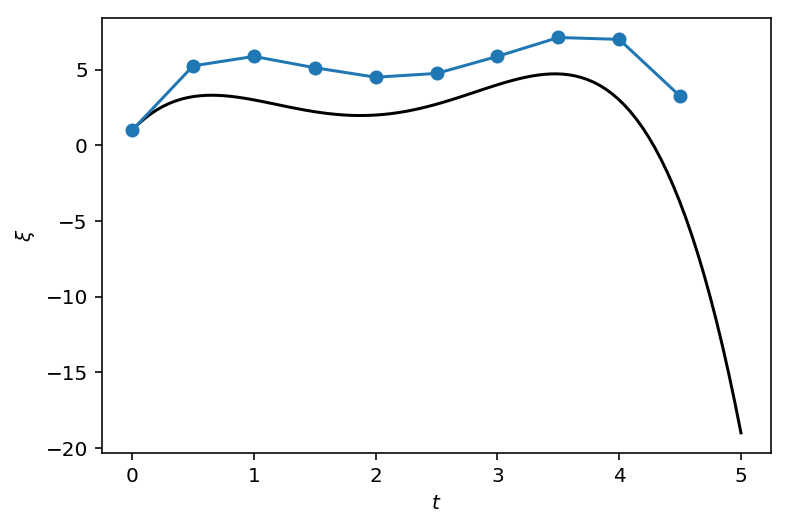

In [5]:
# plot the analytic and numeric solution

fig, ax = plt.subplots()
ax.plot(t_a,xi_a, 'k')
ax.plot(t,xi, '-o')
ax.set_xlabel('$t$')
ax.set_ylabel(r'$\xi$');

## Quantitatively compare the numerical and analytic solutions
What's the error between the the two solutions?

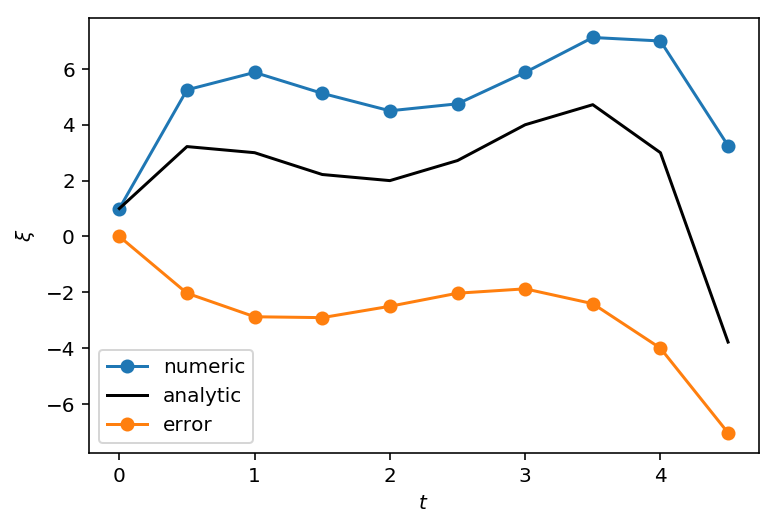

In [6]:
# let's calculate the error at each point

xi_error = (1+8.5*t-10*t**2+4*t**3-0.5*t**4)-xi

fig, ax = plt.subplots()
ax.plot(t,xi, '-o', label='numeric')
ax.plot(t,1+8.5*t-10*t**2+4*t**3-0.5*t**4, 'k', label='analytic')
ax.plot(t,xi_error, '-o', label='error')
ax.set_xlabel('$t$')
ax.set_ylabel(r'$\xi$')
plt.legend();

In [7]:
# let's look at the error values
print('the error at each point is \n', xi_error)
print('\n sum of the error^2 at each point =', np.around(np.sum(xi_error**2),decimals =2))

the error at each point is 
 [ 0.      -2.03125 -2.875   -2.90625 -2.5     -2.03125 -1.875   -2.40625
 -4.      -7.03125]

 sum of the error^2 at each point = 105.96


## How could we improve the prediction?

In [8]:
# let's first write this using functions

def xi_analytic(t):
    return 1+8.5*t-10*t**2+4*t**3-0.5*t**4

def g(t):
    return -2*t**3+12*t**2-20*t+8.5

sum of the error^2 at each point = 29.79


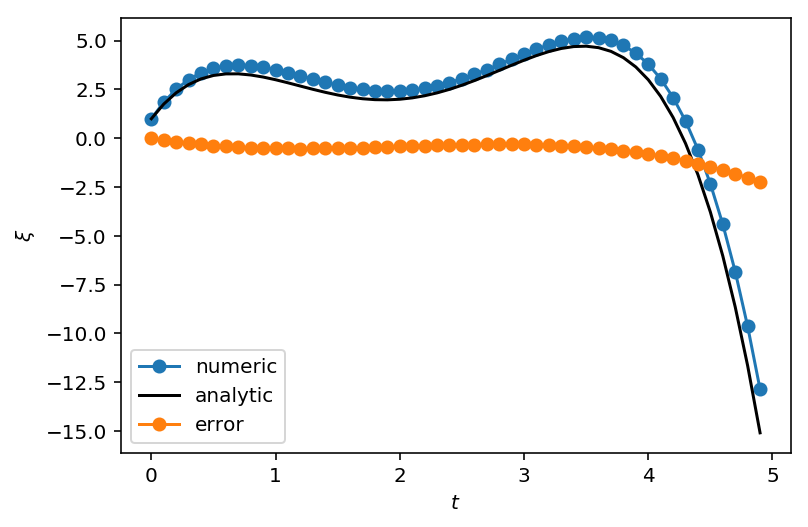

In [9]:
# set the time step
dt = 0.1

# setup the numerical wave
t = np.arange(0,tend,dt)
N = len(t)
xi = np.zeros(N)
xi[0]=xi0

# calculate xi numerically
for i in range(0,N-1):
    xi[i+1]=xi[i]+dt*g(t[i])

# setup the analytic wave
xi_a = xi_analytic(t)

# calculate the error 
xi_error = xi_a - xi

# plot and print the error
fig, ax = plt.subplots()
ax.plot(t,xi, '-o', label='numeric')
ax.plot(t,1+8.5*t-10*t**2+4*t**3-0.5*t**4, 'k', label='analytic')
ax.plot(t,xi_error, '-o', label='error')
ax.set_xlabel('$t$')
ax.set_ylabel(r'$\xi$')
plt.legend()
print('sum of the error^2 at each point =', np.around(np.sum(xi_error**2), decimals=2));